# Amostragem Adaptativa com LLM JUDGE

In [1]:

# ==========================================
# 1. Deep Learning e modelos de linguagem
# ==========================================
import torch
import random
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

# ==========================================
# 2. Hugging Face e datasets
# ==========================================
from datasets import load_dataset
from huggingface_hub import login, snapshot_download

# ==========================================
# 3. Processamento e análise de dados
# ==========================================
import numpy as np
import pandas as pd

# ==========================================
# 4. Avaliação e métricas
# ==========================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# ==========================================
# 5. Execução e experimentação
# ==========================================
from tqdm.auto import tqdm
from dotenv import load_dotenv
import json

# ==========================================
# 6. Visualização
# ==========================================
import matplotlib.pyplot as plt

# ==========================================
# 7. Arquivos e configurações
# ==========================================
import jsonlines
from pathlib import Path
import re
from collections import Counter
from scipy.stats import beta

# Leitura do arquivo

In [2]:
# carregamento do gsm8k

gsm8k = load_dataset("openai/gsm8k", "main")

gsm8k_train = gsm8k["train"]
gsm8k_test = gsm8k["test"]

print(gsm8k)
print(gsm8k_test[0])


DatasetDict({
    train: Dataset({
        features: ['question', 'answer'],
        num_rows: 7473
    })
    test: Dataset({
        features: ['question', 'answer'],
        num_rows: 1319
    })
})
{'question': "Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?", 'answer': 'Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.\nShe makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.\n#### 18'}


In [3]:
# sorteando os problemas
seed = 42 
n_problemas = 200
rng = random.Random(seed)
indices = random.sample(range(len(gsm8k_test)), n_problemas)

dados = {'seed': seed,
         'n_problemas': n_problemas,
         'indices': sorted(indices)}

with open('dados.json', 'w', encoding='utf-8') as arquivo:
    json.dump(dados, arquivo, indent=2, ensure_ascii=False)



In [4]:
with open("problems.jsonl", "r", encoding="utf-8") as f:
    registros = [json.loads(linha) for linha in f]

reg = registros[0]

In [5]:
mt_human = load_dataset("lmsys/mt_bench_human_judgments")
print(mt_human)

DatasetDict({
    gpt4_pair: Dataset({
        features: ['question_id', 'model_a', 'model_b', 'winner', 'judge', 'conversation_a', 'conversation_b', 'turn'],
        num_rows: 2400
    })
    human: Dataset({
        features: ['question_id', 'model_a', 'model_b', 'winner', 'judge', 'conversation_a', 'conversation_b', 'turn'],
        num_rows: 3355
    })
})


In [6]:
def extrair_gabarito(answer):
    texto = answer.split("####")[-1].strip()
    return float(texto.replace(',', ''))

problemas= []

for i in indices:
    exemplo = gsm8k_test[i]
    problemas.append({
        'indice': i,
        'pergunta': exemplo['question'],
        'gabarito': extrair_gabarito(exemplo['answer'])
    })

with open('problems.jsonl', 'w', encoding='utf-8') as arquivo:
    for p in problemas:
        arquivo.write(json.dumps(p, ensure_ascii=False) + '\n')
        
print(len(problemas))
for p in problemas[:5]:
    print(p['indice'], p['gabarito'])

200
85 44.0
517 18.0
916 14.0
617 5.0
1258 60.0


In [7]:
print(gsm8k_test[24]["answer"])

Let X be the original price of the book. The discounted price is X - X*25% = $19.50.
Combining like terms, we get .75X = $19.50
Dividing both sides by .75, we get X = $26.
#### 26


## Agora aplicamos o tokenizador 

In [8]:
gerador_id = 'Qwen/Qwen2.5-1.5B-Instruct'

judge_id = 'Qwen/Qwen3-8B'

# Carrega o tokenizador
tokenizer = AutoTokenizer.from_pretrained(gerador_id)

# Carrega o modelo na GPU com precisão float16
gerador = AutoModelForCausalLM.from_pretrained(
    gerador_id, device_map="cuda", torch_dtype=torch.float16
)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

# Montagem do prompt para o tokenizador

In [9]:
pergunta = "Se um trem viaja a 80 km/h por 2,5 horas, qual distância ele percorre?"

mensagens = [
    {
        'role': 'user',
        'content': (
            f'{pergunta}\n\n'
            "Raciocine passo a passo antes de responder e termine sua resposta "
            "exatamente com uma linha no formato: Resposta final: <número>"
        ),
    }
]

# aplica o template do chat do modelo e prepara os tensores da gpu 
inputs = tokenizer.apply_chat_template(
    mensagens, add_generation_prompt=True, return_tensors="pt"
).to("cuda")

prompt_formatado = tokenizer.apply_chat_template(
    mensagens, tokenize=False, add_generation_prompt=True
)
print(prompt_formatado)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Se um trem viaja a 80 km/h por 2,5 horas, qual distância ele percorre?

Raciocine passo a passo antes de responder e termine sua resposta exatamente com uma linha no formato: Resposta final: <número><|im_end|>
<|im_start|>assistant



# Gerando novos tokens

In [10]:
with torch.no_grad():
    outputs = gerador.generate(
        **inputs, 
        max_new_tokens = 512,
        do_sample = True,
        temperature = 0.7,
        pad_token_id = tokenizer.eos_token_id,
    )

tamanho_prompt = inputs["input_ids"].shape[-1]
novos_tokens = outputs[0][tamanho_prompt:]

resposta = tokenizer.decode(novos_tokens, skip_special_tokens = True)
print(resposta)

Passo 1: Identificar as informações fornecidas.
- Velocidade do trem = 80 km/h (quilômetros por hora)
- Tempo de viagem = 2,5 horas

Passo 2: Calcular a distância percorrida usando a fórmula da velocidade:
Distância = Velocidade × Tempo

Substituindo os valores:
Distância = 80 km/h × 2,5 h

Passo 3: Realizar o cálculo:
Distância = 200 km

Resposta final: 200


In [11]:
def extrair_resposta(texto):
    # Remove separadores de milhar (ex: 1.000 ou 1,000) se necessário,
    # mas aqui focamos em capturar números inteiros, decimais e negativos.
    padrao_num = r"-?\d+(?:[.,]\d+)?"

    resposta = re.search(r"Resposta final:(.*)", texto, flags = re.IGNORECASE | re.DOTALL)

    if resposta:
        trecho = resposta.group(1).replace(',', '')
        numeros = re.findall(padrao_num, trecho)

        if numeros:
            return float(numeros[0])

    numeros = re.findall(padrao_num, texto.replace(',', ''))
    if numeros:
        return float(numeros[-1])
    return None


In [12]:
print(extrair_resposta("Total. Resposta final: 1,250"))      # 1250.0
print(extrair_resposta("Resposta final: $18.50."))           # 18.5
print(extrair_resposta("então são 42 maçãs."))               # 42.0
print(extrair_resposta("não sei"))                           # None

1250.0
18.5
42.0
None


# Função de geração de respostas 

In [13]:
def gerar_respostas(pergunta, k=4):
    prompt = pergunta + "\n\nResolva passo a passo. Termine com: Resposta final: <número>"
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to(gerador.device)

    with torch.no_grad():
        saidas = gerador.generate(
            **inputs,
            max_new_tokens=512,
            do_sample=True,
            temperature=0.7,
            num_return_sequences=k,
            pad_token_id=tokenizer.eos_token_id,
        )

    n = inputs["input_ids"].shape[-1]
    return tokenizer.batch_decode(saidas[:, n:], skip_special_tokens=True)

## Testando com 3 problemas(Mais leve)

In [14]:
import time

In [15]:
inicio = time.time()
registros = []

for p in problemas[:3]:
    textos = gerar_respostas(p["pergunta"], k=4)
    numeros = [extrair_resposta(t) for t in textos]
    registros.append({**p, "respostas": [{"texto": t, "numero": n} for t, n in zip(textos, numeros)]})
    print(p["indice"], p["gabarito"], numeros)

with open("teste_respostas.jsonl", "w", encoding="utf-8") as f:
    for r in registros:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print("tempo:", round(time.time() - inicio, 1), "s")

85 44.0 [44.0, 44.0, 44.0, 8136.0]
517 18.0 [18.0, 18.0, 18.0, 18.0]
916 14.0 [10.33, 12.5, 9.5, 7.5]
tempo: 18.3 s



Simulamos a parada sobre as respostas já salvas, para comparar todas as estratégias nas mesmas amostras"

In [16]:
def votar(numeros):
    validos = [n for n in numeros if n is not None]
    return Counter(validos).most_common(1)[0][0] if validos else None

def parar(numeros, limiar = 0.95):
    top = Counter(n for n in numeros if n is not None).most_common(2)
    if not top:
        return False

    v1 = top[0][1]
    v2 = top[1][1] if len(top) > 1 else 0
    return beta.sf(0.5, v1 + 1, v2 + 1) >= limiar

def adaptativa(numeros, limiar=0.95):
    for i in range(1, len(numeros) + 1):
        if parar(numeros[:i], limiar):
            return votar(numeros[:i]), i
    return votar(numeros), len(numeros)

def acertou(resposta, gabarito):
    return resposta is not None and abs(resposta - gabarito) < 1e-6

In [19]:
reg = registros[0]
print(reg.keys())

dict_keys(['indice', 'pergunta', 'gabarito', 'respostas'])


In [20]:
numeros = [r["numero"] for r in reg["respostas"]]
respos = votar(numeros[:8])
resp, n_gens = adaptativa(numeros)
print(numeros, respos, resp, n_gens)

[44.0, 44.0, 44.0, 8136.0] 44.0 44.0 4


In [ ]:
with open('respostas.jsonl', "w", encoding='utf-8') as f:
    for p in tqdm(problemas):
        textos = gerar_respostas(p['pergunta'], k =8) + gerar_respostas(p['pergunta'], k = 8)
        numeros = [extrair_resposta(t) for t in textos]

        p["respostas"] = [{"texto": t, "numero": n} for t, n in zip(textos, numeros)]
        f.write(json.dumps(p, ensure_ascii=False) + "\n")


  0%|          | 0/200 [00:00<?, ?it/s]

AttributeError: 'str' object has no attribute 'read'

In [23]:
with open('respostas.jsonl', 'r', encoding='utf-8') as f:
    registros = [json.loads(linha) for linha in f]
print(len(registros))

200


In [24]:
# comparar as estratégias
linhas = []
for reg in registros:
    numeros = [r["numero"] for r in reg["respostas"]]
    gab = reg["gabarito"]
    resp, n = adaptativa(numeros)
    linhas.append({
        "fixa_4": acertou(votar(numeros[:4]), gab),
        "fixa_8": acertou(votar(numeros[:8]), gab),
        "fixa_16": acertou(votar(numeros), gab),
        "adapt": acertou(resp, gab),
        "gens": n,
    })

df = pd.DataFrame(linhas)
print(df.mean())

fixa_4      0.590
fixa_8      0.660
fixa_16     0.745
adapt       0.745
gens       11.105
dtype: float64


In [32]:
import os

In [34]:
feitos = set()
if os.path.exists('respostas.jsonl'):
    with open('respostas.jsonl', 'r', encoding='utf-8') as f:
        feitos = {json.loads(linha)["indice"] for linha in f}

with open('respostas.jsonl', 'a', encoding='utf-8') as f:
    for p in tqdm(problemas):
        if p["indice"] in feitos:
            continue
        textos = gerar_respostas(p['pergunta'], k=16)
        numeros = [extrair_resposta(t) for t in textos]
        p["respostas"] = [{"texto": t, "numero": n} for t, n in zip(textos, numeros)]
        f.write(json.dumps(p, ensure_ascii=False) + "\n")
        f.flush() 

  0%|          | 0/200 [00:00<?, ?it/s]

# Anãlise exploratória

In [25]:
# 1. respostas sem número (checar a extração)
nones = sum(r["numero"] is None for reg in registros for r in reg["respostas"])
print(nones, "sem número de", len(registros) * 16)

0 sem número de 3200


In [26]:
# 2. adaptativa com dois limiares
def rodar(limiar):
    acertos, gens, paradas_erradas = [], [], 0
    for reg in registros:
        numeros = [r["numero"] for r in reg["respostas"]]
        resp, n = adaptativa(numeros, limiar)
        ok = acertou(resp, reg["gabarito"])
        acertos.append(ok)
        gens.append(n)
        if n < len(numeros) and not ok:
            paradas_erradas += 1
    return np.mean(acertos), np.mean(gens), paradas_erradas

acc95, gens95, err95 = rodar(0.95)
acc90, gens90, err90 = rodar(0.90)

In [27]:
# 3. tabela final
tabela = pd.DataFrame({
    "estratégia": ["fixa 4", "fixa 8", "fixa 16", "adaptativa 0.95", "adaptativa 0.90"],
    "acurácia": [df["fixa_4"].mean(), df["fixa_8"].mean(), df["fixa_16"].mean(), acc95, acc90],
    "gerações (média)": [4, 8, 16, gens95, gens90],
})
print(tabela.round(3))
tabela.to_csv("resultados.csv", index=False)

        estratégia  acurácia  gerações (média)
0           fixa 4     0.590             4.000
1           fixa 8     0.660             8.000
2          fixa 16     0.745            16.000
3  adaptativa 0.95     0.745            11.105
4  adaptativa 0.90     0.745             9.860


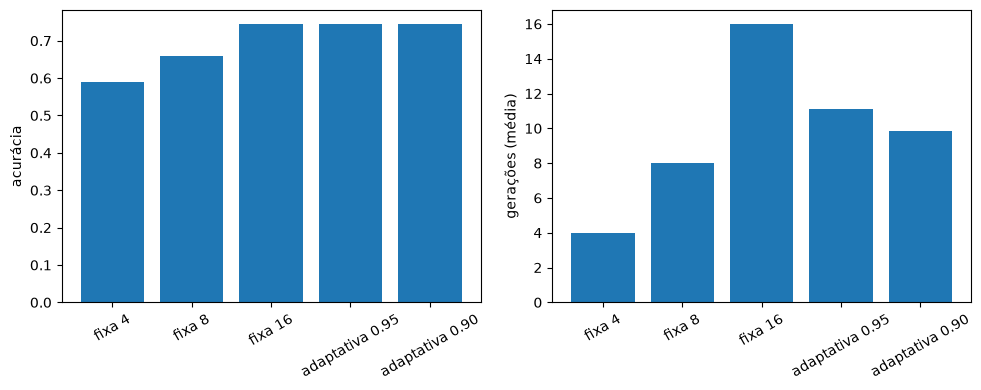

In [28]:
# 5. gráficos
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].bar(tabela["estratégia"], tabela["acurácia"])
ax[0].set_ylabel("acurácia")
ax[0].tick_params(axis="x", rotation=30)

ax[1].bar(tabela["estratégia"], tabela["gerações (média)"])
ax[1].set_ylabel("gerações (média)")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("resultados.png", dpi=150)
plt.show()

In [29]:
# 6. quantos problemas o voto majoritário erra mesmo com a maioria concordando
erros_fixa16 = (~df["fixa_16"]).sum()
print("problemas errados na fixa 16:", erros_fixa16, "de", len(df))

problemas errados na fixa 16: 51 de 200


In [30]:
# 7. quantos problemas nem 16 respostas resolvem
print("errados na fixa 16:", (~df["fixa_16"]).sum(), "de", len(df))

errados na fixa 16: 51 de 200
